# Experiments
See tex/main.pdf, Sections 2.4 to 2.6.

All experiments use Bernoulli noise with $p = 0.8$ (20% of the labels flipped). When the noise level varies, we use $p \in \{0.6, 0.8, 0.95\}$, i.e. 40%, 20%, 5% noise.

In [8]:
%run base.ipynb

mare


In [6]:
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
num_iter = 100
num_crossings = 10
noise_par = 0.8
my_noise_pars = [0.6, 0.8, 0.95]
my_nums_crossings = [5, 10, 50]

from functools import partial
sine_f = partial(sine, m = num_crossings)

def noise_label(p):
    # noise level as percentage of flipped labels
    return f'{(1 - p) * 100:.0f}% noise'

# same depths that main_loop and plots use
depths, _ = get_depths_list(np.log2(data_size_tr), mymodel)

## Union bound

We plot
\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \sqrt{\frac{d}{n}}
\end{equation}
obtained by Theorem 2.5 in Section 2 and $\log \vert\mathcal H_d\vert \le d$.

[checkpoint] bound: "unionbound" -> union_bound, params: []


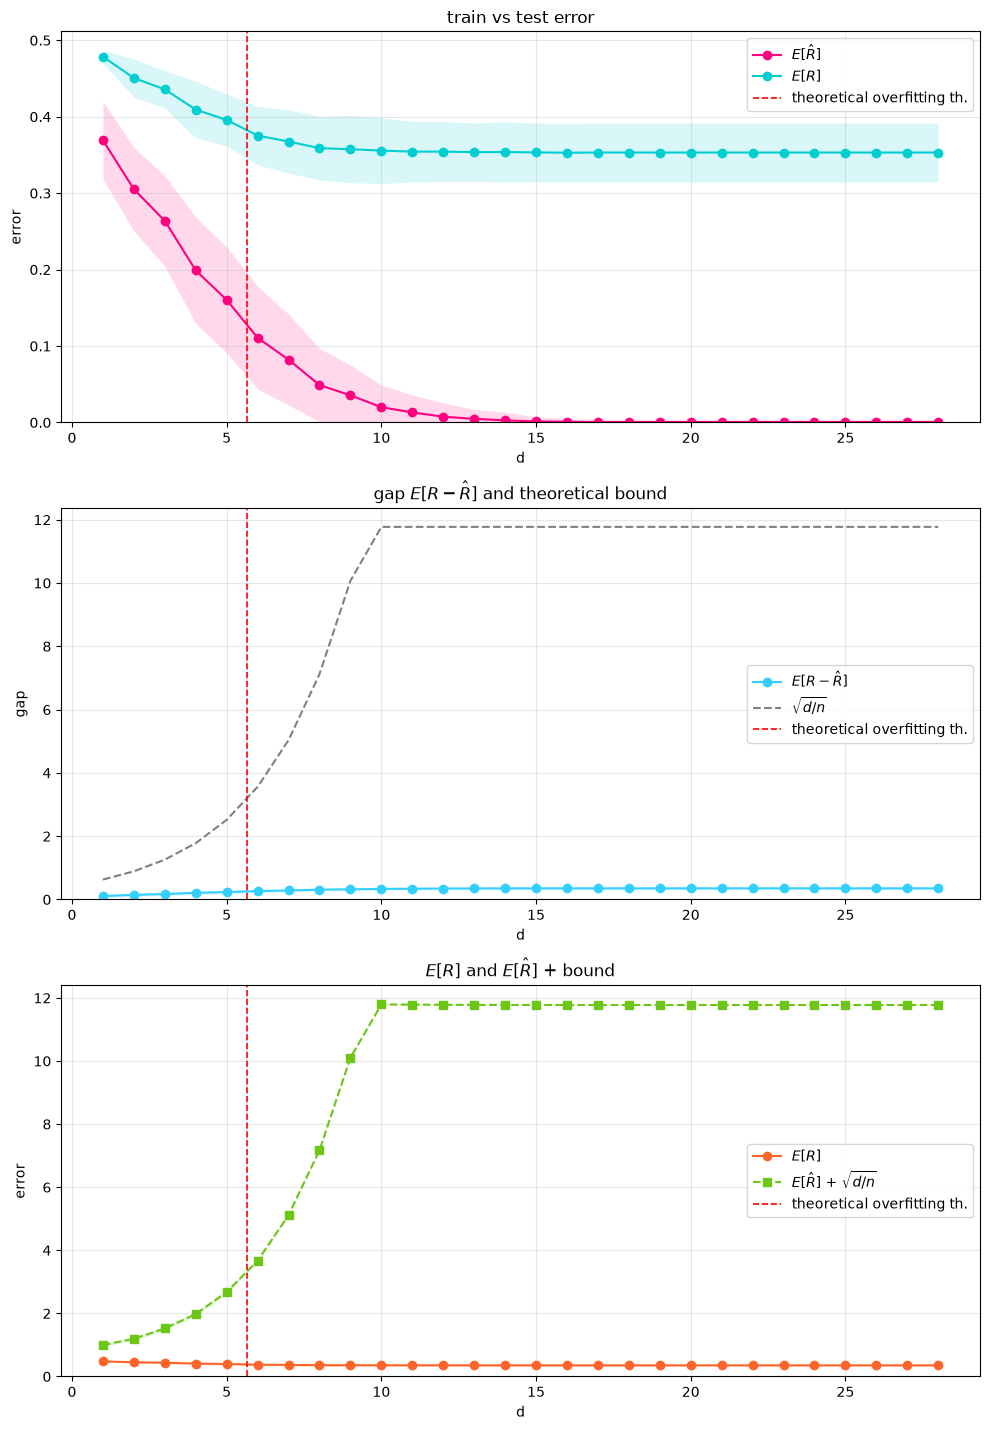

In [9]:
# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x = x_test, f = sine_f, p = noise_par)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, p = noise_par, T = num_iter, model = mymodel,
    f = sine_f, noise_type = "bernoulli",
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "bernoulli", p = noise_par, T = num_iter, model = mymodel, 
      bound_name = "unionbound", bound_params = {}
      )

## Rademacher + Massart

We plot

\begin{equation}
\mathbb E_D[R(\hat h_D) - \hat R_D(\hat h_D)] \le \min\left\{\sqrt{\frac{d}{n}}, 1\right\}
\end{equation}

obtained from $N(D) \le \min\{\vert \mathcal H\vert, 2^n\}$, equation (58). Same models as above, only the bound changes.

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


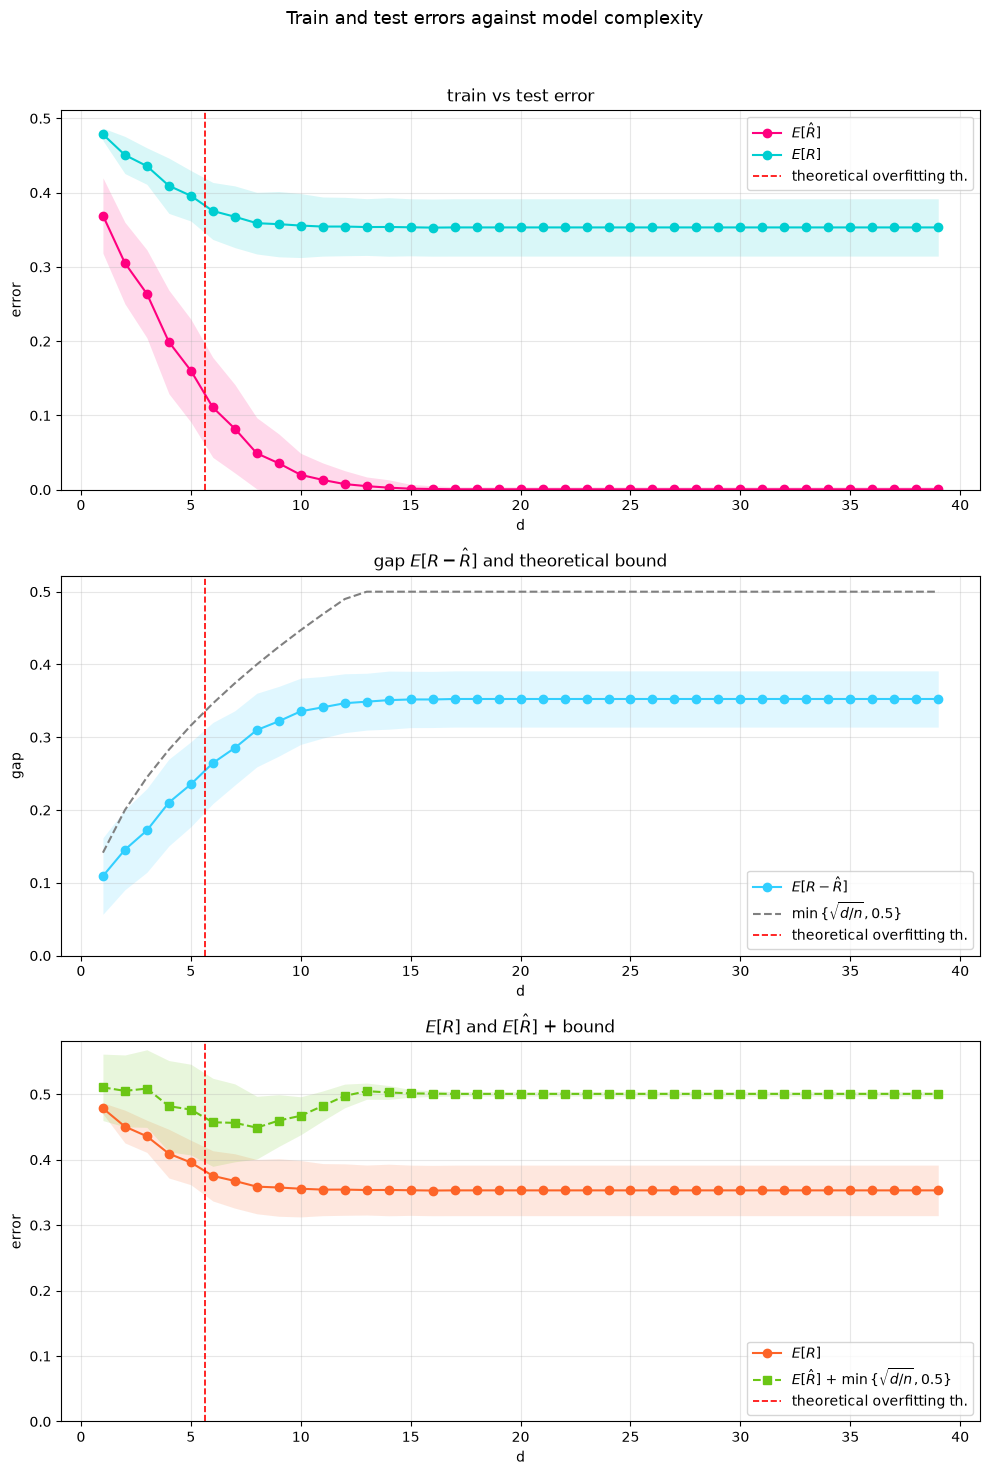

In [4]:
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "bernoulli", p = noise_par, T = num_iter, model = mymodel, 
      bound_name = "rademmassart", bound_params = {}
      )

### vedi che non si sposta con il rumore!

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


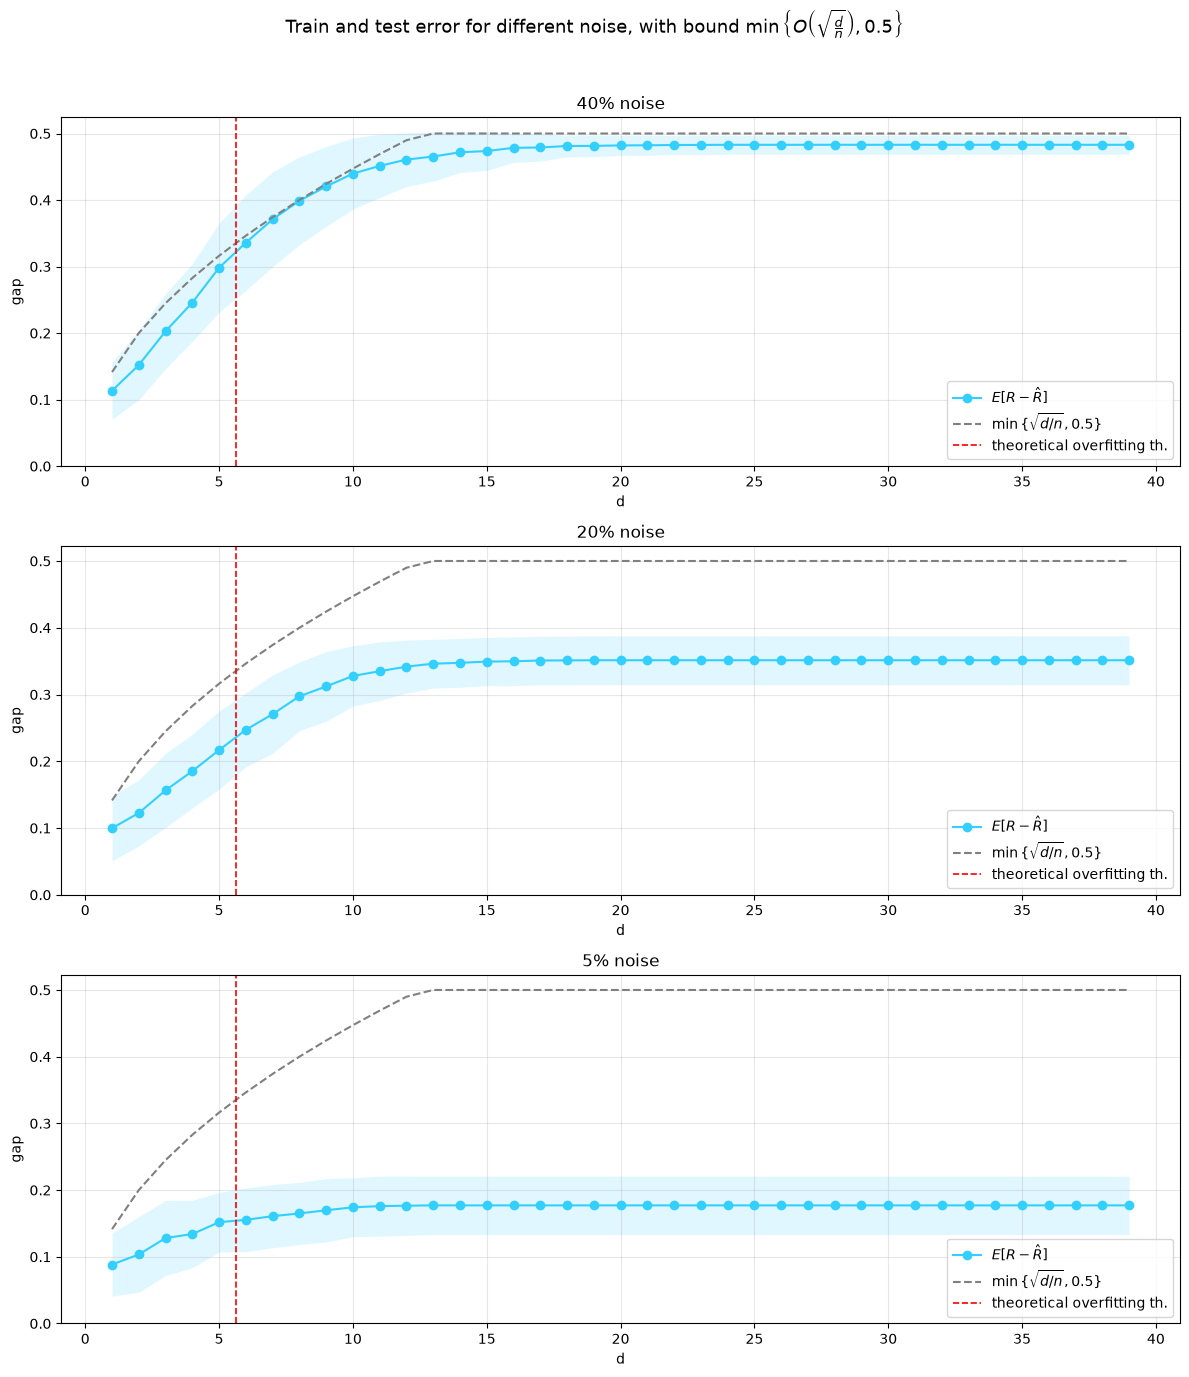

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=sine_f, p=my_noise_par)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=my_noise_par, T=num_iter, model=mymodel, f=sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=my_noise_par, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.set_title(noise_label(my_noise_par))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### e con la complessità della funzione?

[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []
[checkpoint] bound: "rademmassart" -> radem_massart_bound, params: []


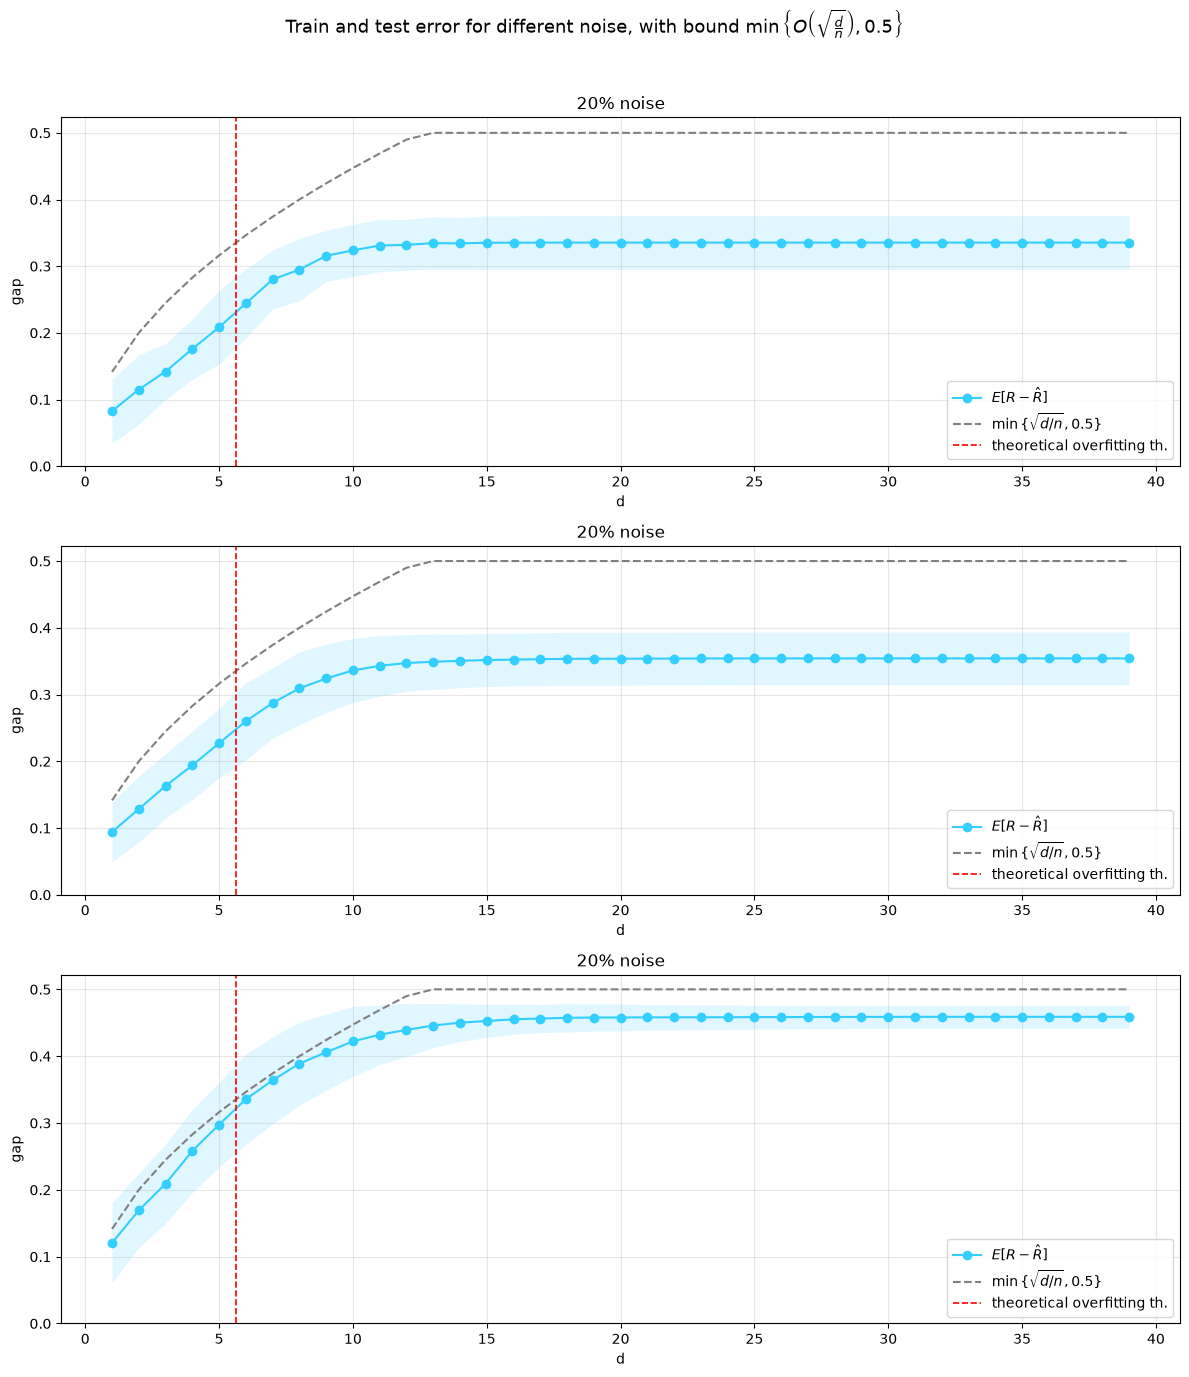

In [3]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_num_crossings in zip(axs.flat, my_nums_crossings):
    my_sine_f = partial(sine, m = my_num_crossings)
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=my_sine_f, p=noise_par)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=noise_par, T=num_iter, model=mymodel, f=my_sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=noise_par, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "rademmassart", bound_params = {})
    ax.set_title(noise_label(noise_par))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Bounds with the best risk

The bound is 

\begin{equation}
 \min\left\{ 
\sqrt{\frac{(A_{\mathcal H}+\sigma^2)\log \vert\mathcal H \vert}{n}} + \frac{\log\vert\mathcal H \vert}{n} ,
\sqrt{A_{\mathcal H}+\sigma^2} \right\}
\end{equation}

Let's first see the Bayes risk (irreducible noise), the minimum risk achievable by our hypotheses, and their difference (approximation error).

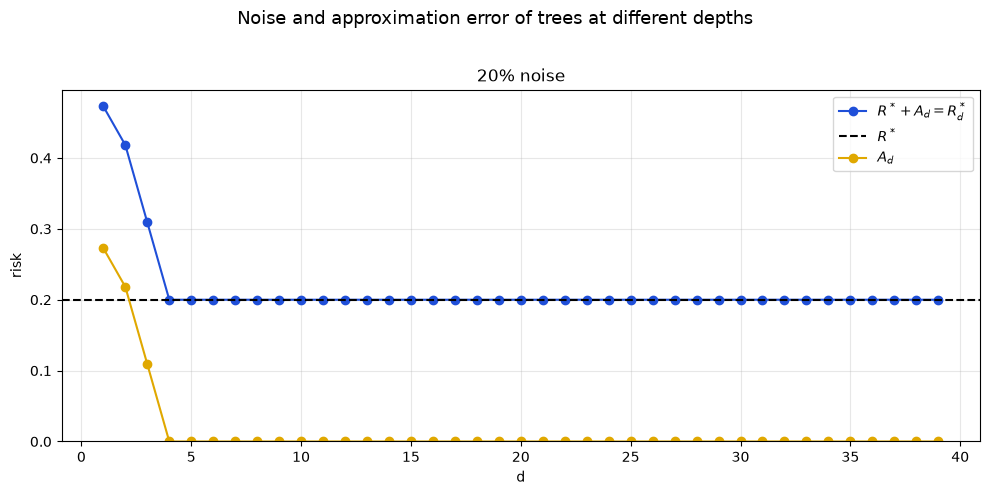

In [ ]:
R_star_d = dp_R_star_d(sine_f, depths, N = supp_size, p = noise_par)

R_star = 1-noise_par

A_d = R_star_d - R_star

def plot_noise_approxerr(ax, depths, R_star_d, R_star):
    # colors on purpose different from the ones used in plots() for the errors
    ax.plot(depths, R_star_d, color='#1F4FD8', marker='o', label=r'$R^* + A_d = R^*_d$')
    ax.axhline(R_star, color='k', linestyle='--', label=r'$R^*$')
    ax.plot(depths, R_star_d - R_star, color='#E0A800', marker='o', label=r'$A_d$')
    ax.set_ylim(bottom=0)
    ax.set_xlabel('d'); ax.set_ylabel('risk')
    ax.legend(); ax.grid(True, alpha=0.3)

fig, ax = plt.subplots(figsize=(10, 5))
plot_noise_approxerr(ax, depths, R_star_d, R_star)
ax.set_title(noise_label(noise_par))
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


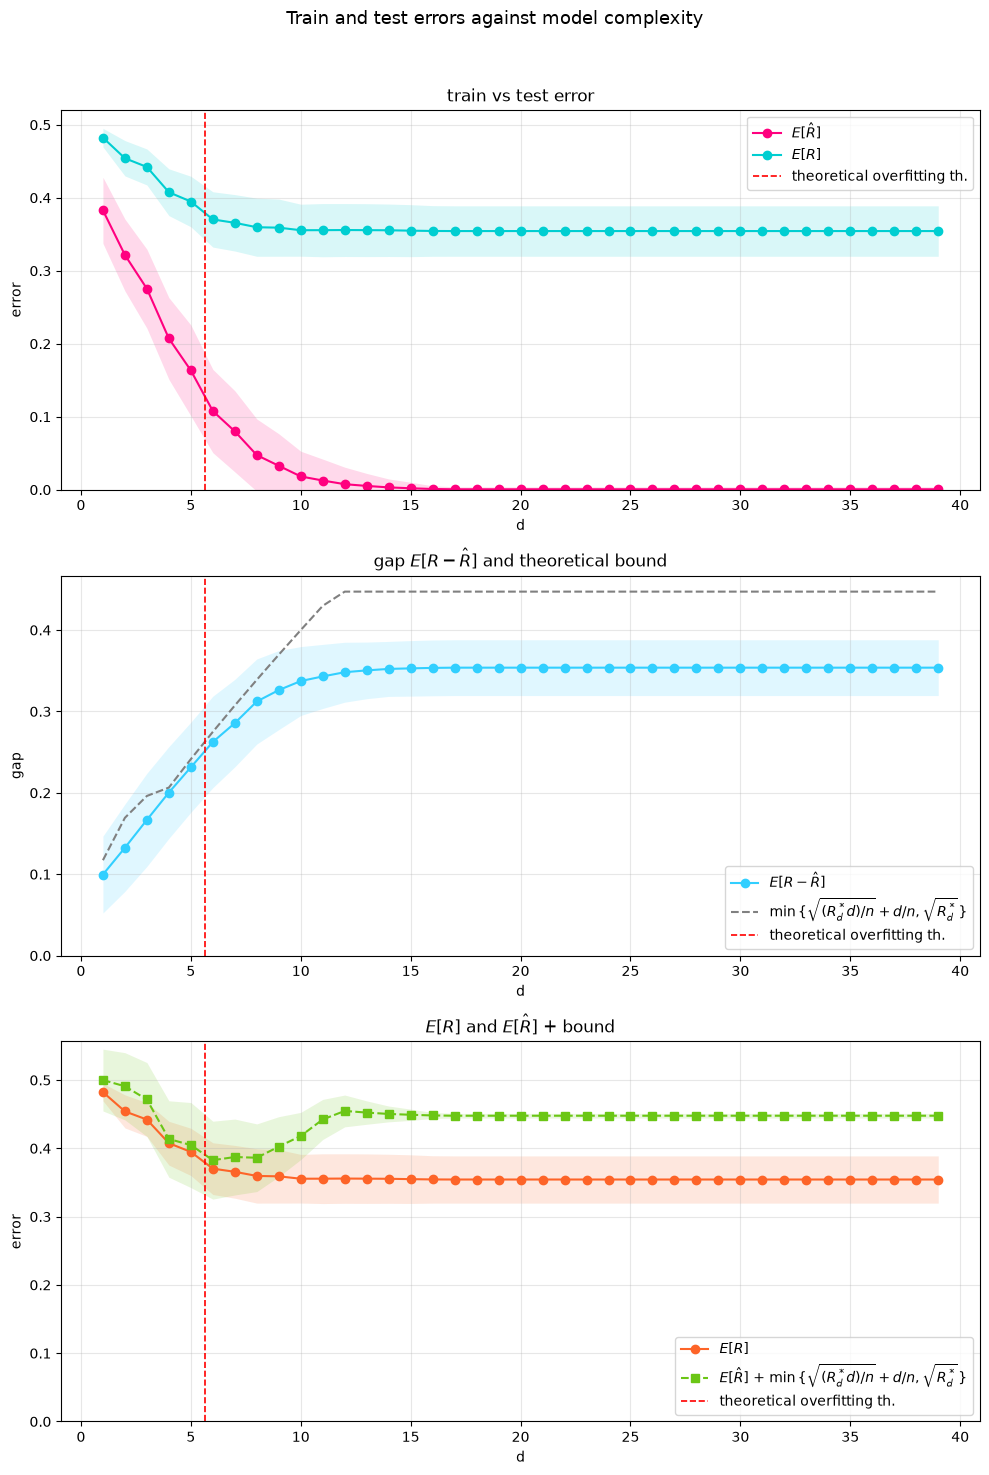

In [ ]:
# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x = x_test, f = sine_f, p = noise_par)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n = data_size_tr, p = noise_par, T = num_iter, model = mymodel,
    f = sine_f, noise_type = "bernoulli",
    N = supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
      n = data_size_tr, noise_type = "bernoulli", p = noise_par, T = num_iter, model = mymodel, 
      bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d}
      )

Let's see it changing!

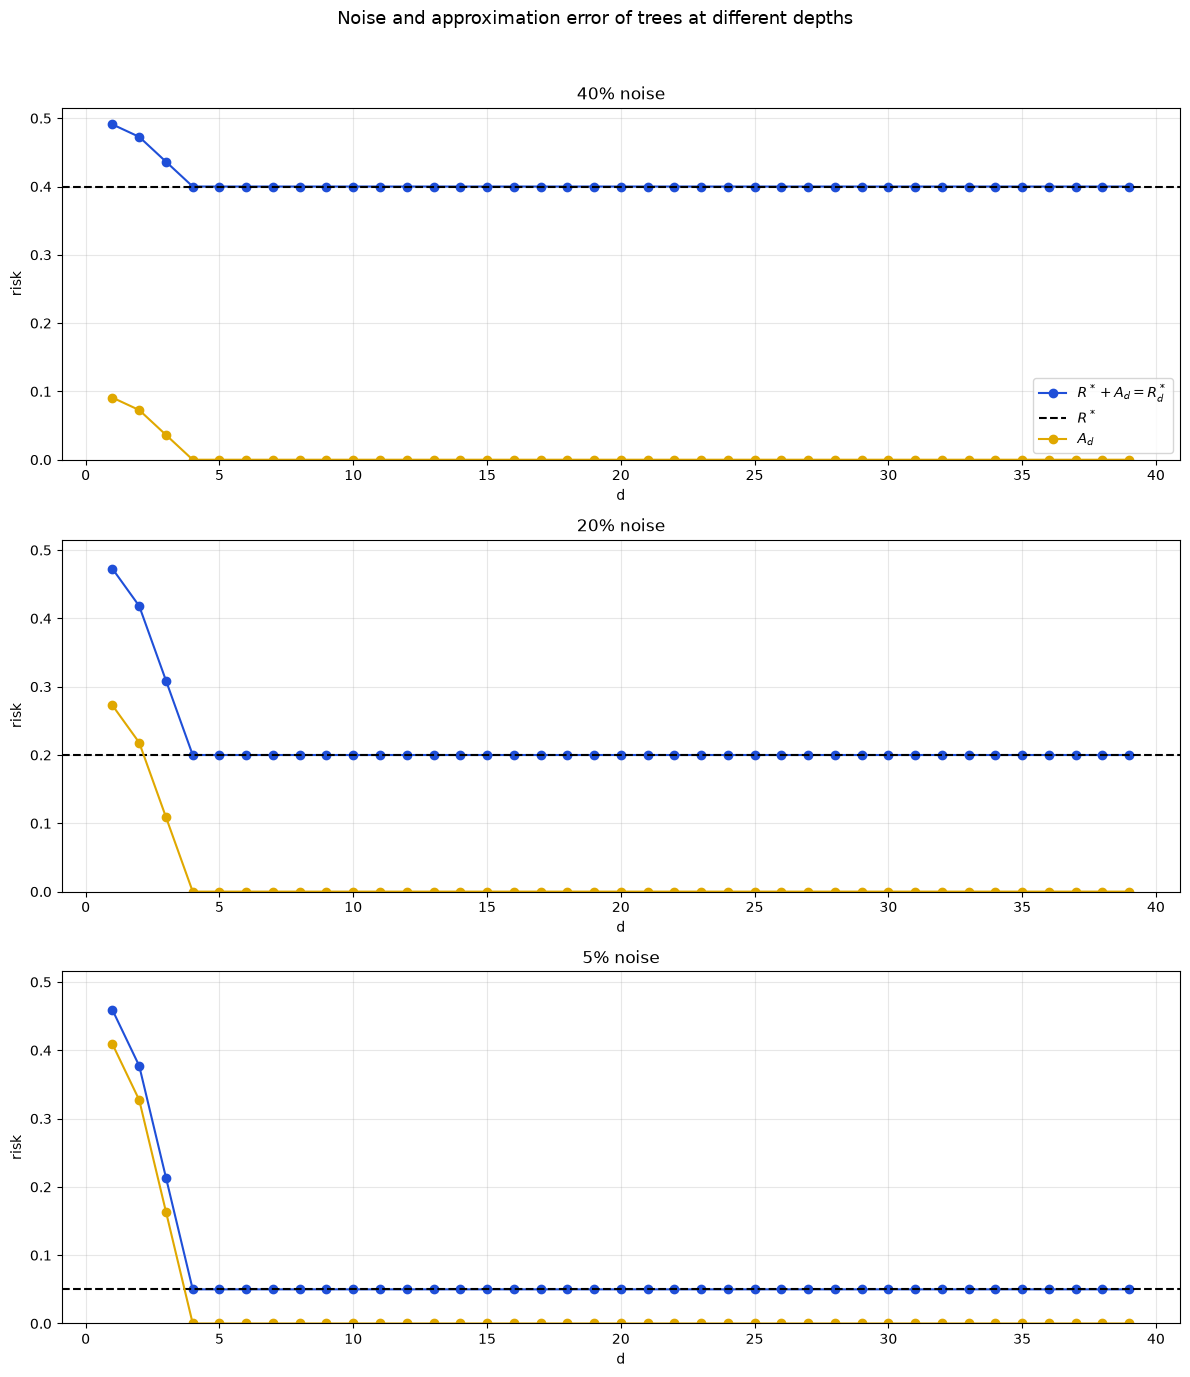

In [ ]:
# R^*_d for each noise level, to reuse in the bounds below
R_star_d_by_p = {}

fig, axs = plt.subplots(3, 1, figsize=(12, 14), sharey=True)

for ax, my_noise_par in zip(axs, my_noise_pars):
    my_R_star_d = dp_R_star_d(sine_f, depths, N = supp_size, p = my_noise_par)
    my_R_star = 1-my_noise_par
    R_star_d_by_p[my_noise_par] = my_R_star_d

    plot_noise_approxerr(ax, depths, my_R_star_d, my_R_star)
    ax.set_title(noise_label(my_noise_par))
    if ax is not axs[0]:
        ax.get_legend().remove()

# shared y axis: fix the top by hand, set_ylim(bottom=0) freezes it on the first panel
axs[0].set_ylim(0, 1.05 * max(r.max() for r in R_star_d_by_p.values()))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


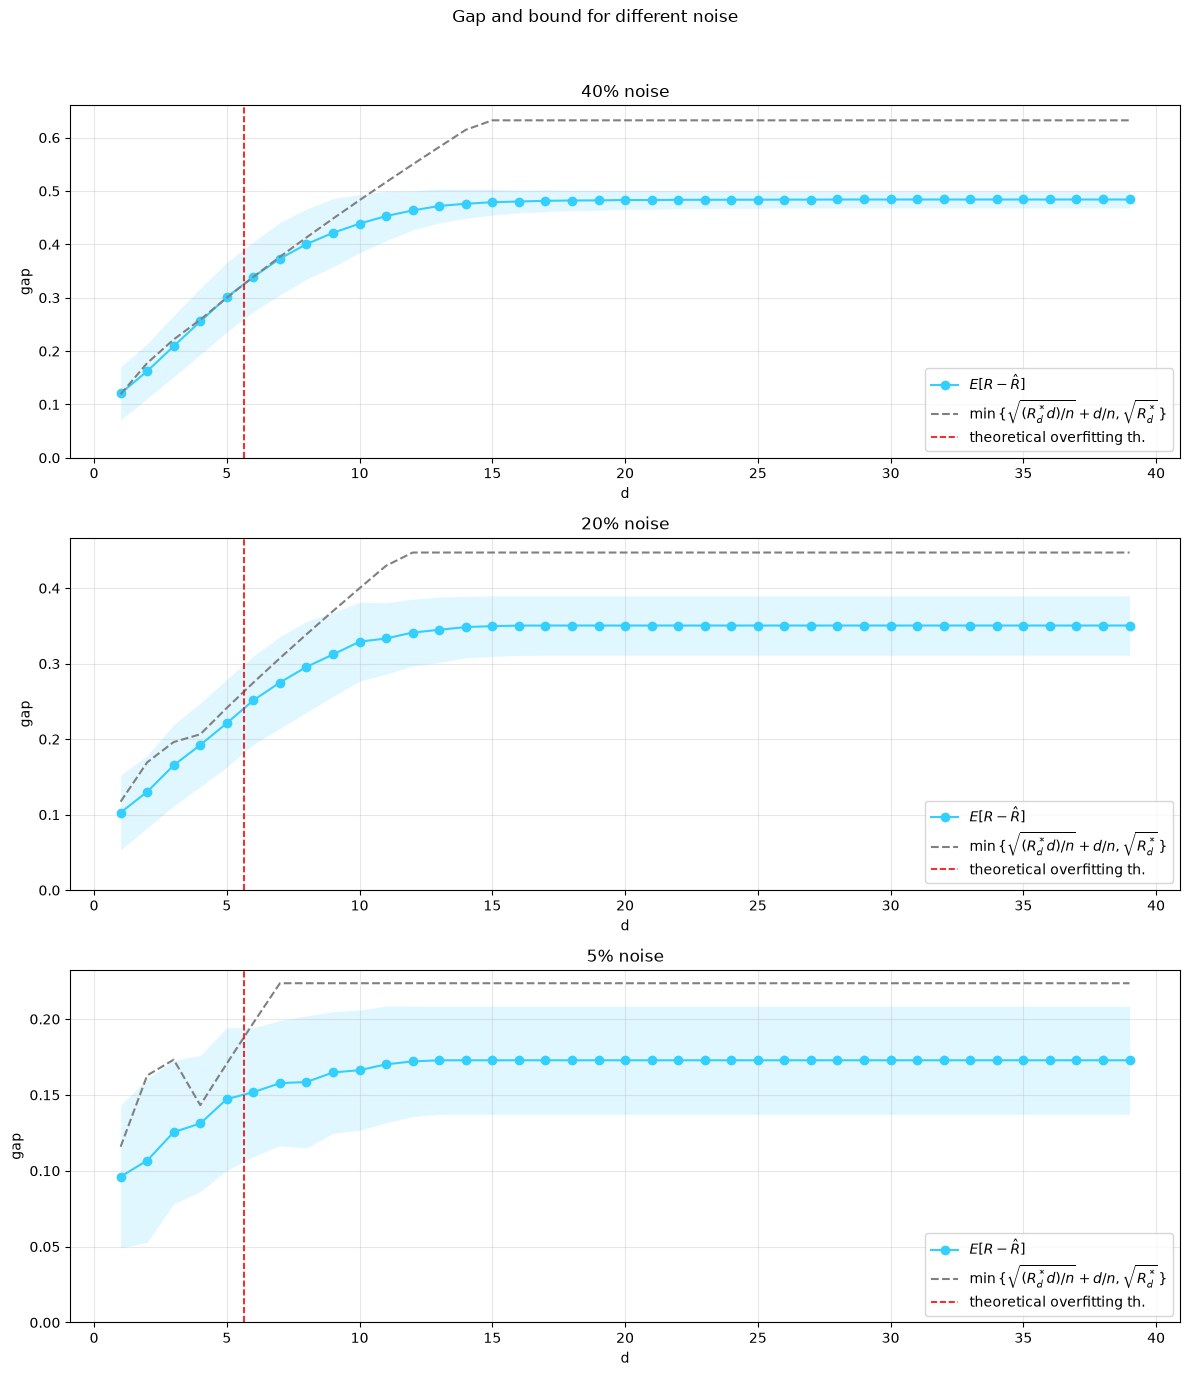

In [ ]:
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=sine_f, p=my_noise_par)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=my_noise_par, T=num_iter, model=mymodel, f=sine_f, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=my_noise_par, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "noiseapproxerr", bound_params = {"R_star_d": R_star_d_by_p[my_noise_par]})
    ax.set_title(noise_label(my_noise_par))

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

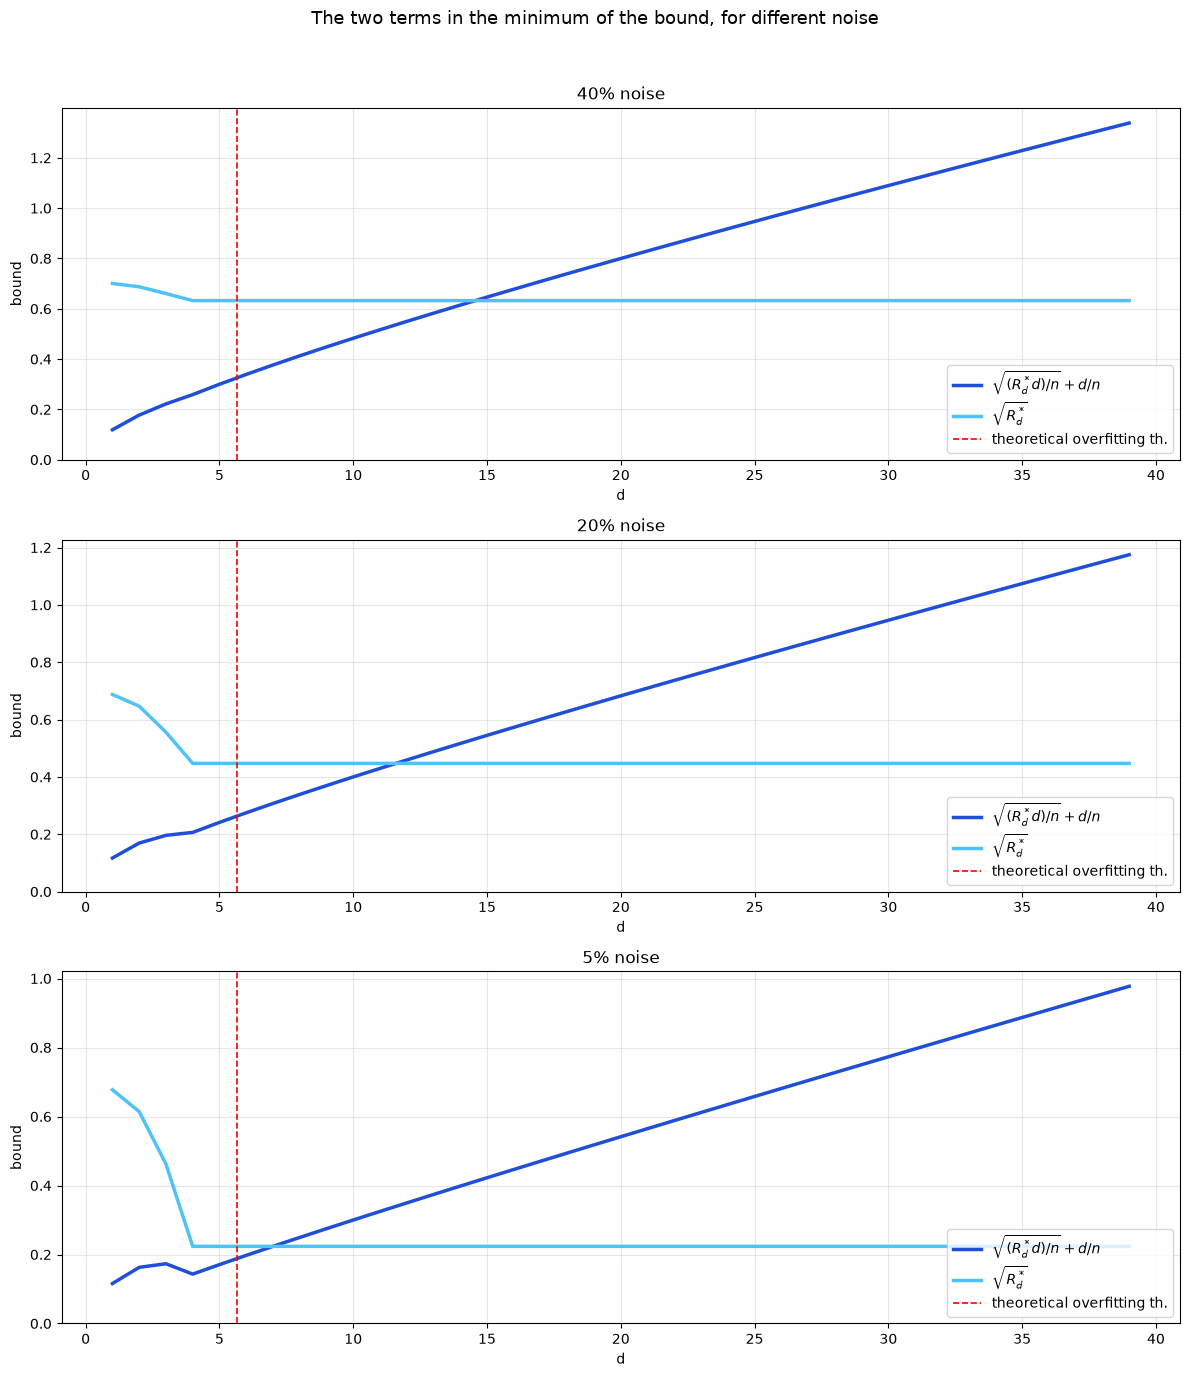

In [10]:
# plot the two terms of the bound 
fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_noise_par in zip(axs.flat, my_noise_pars):
    my_R_star_d = R_star_d_by_p[my_noise_par]
    log_H = log_card_H(depths)

    # same two terms as in noise_approxerr_bound
    term_one = np.sqrt((my_R_star_d * log_H) / data_size_tr) + log_H / data_size_tr
    term_two = np.sqrt(my_R_star_d)

    ax.plot(depths, term_one, color='#1F4FD8', linewidth=2.5, label=r'$\sqrt{(R^*_d d)/n} + d/n$')
    ax.plot(depths, term_two, color='#4FC3F7', linewidth=2.5, label=r'$\sqrt{R^*_d}$')
    ax.axvline(np.log2(data_size_tr), color='red', linestyle='--', linewidth=1.2, label='theoretical overfitting th.')
    ax.set_ylim(bottom=0)
    ax.set_title(noise_label(my_noise_par))
    ax.set_xlabel('d'); ax.set_ylabel('bound')
    ax.legend(loc='lower right'); ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


Same gap and bound as above, at fixed noise, for target functions with different number of crossings $m$.

[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']
[checkpoint] bound: "noiseapproxerr" -> noise_approxerr_bound, params: ['R_star_d']


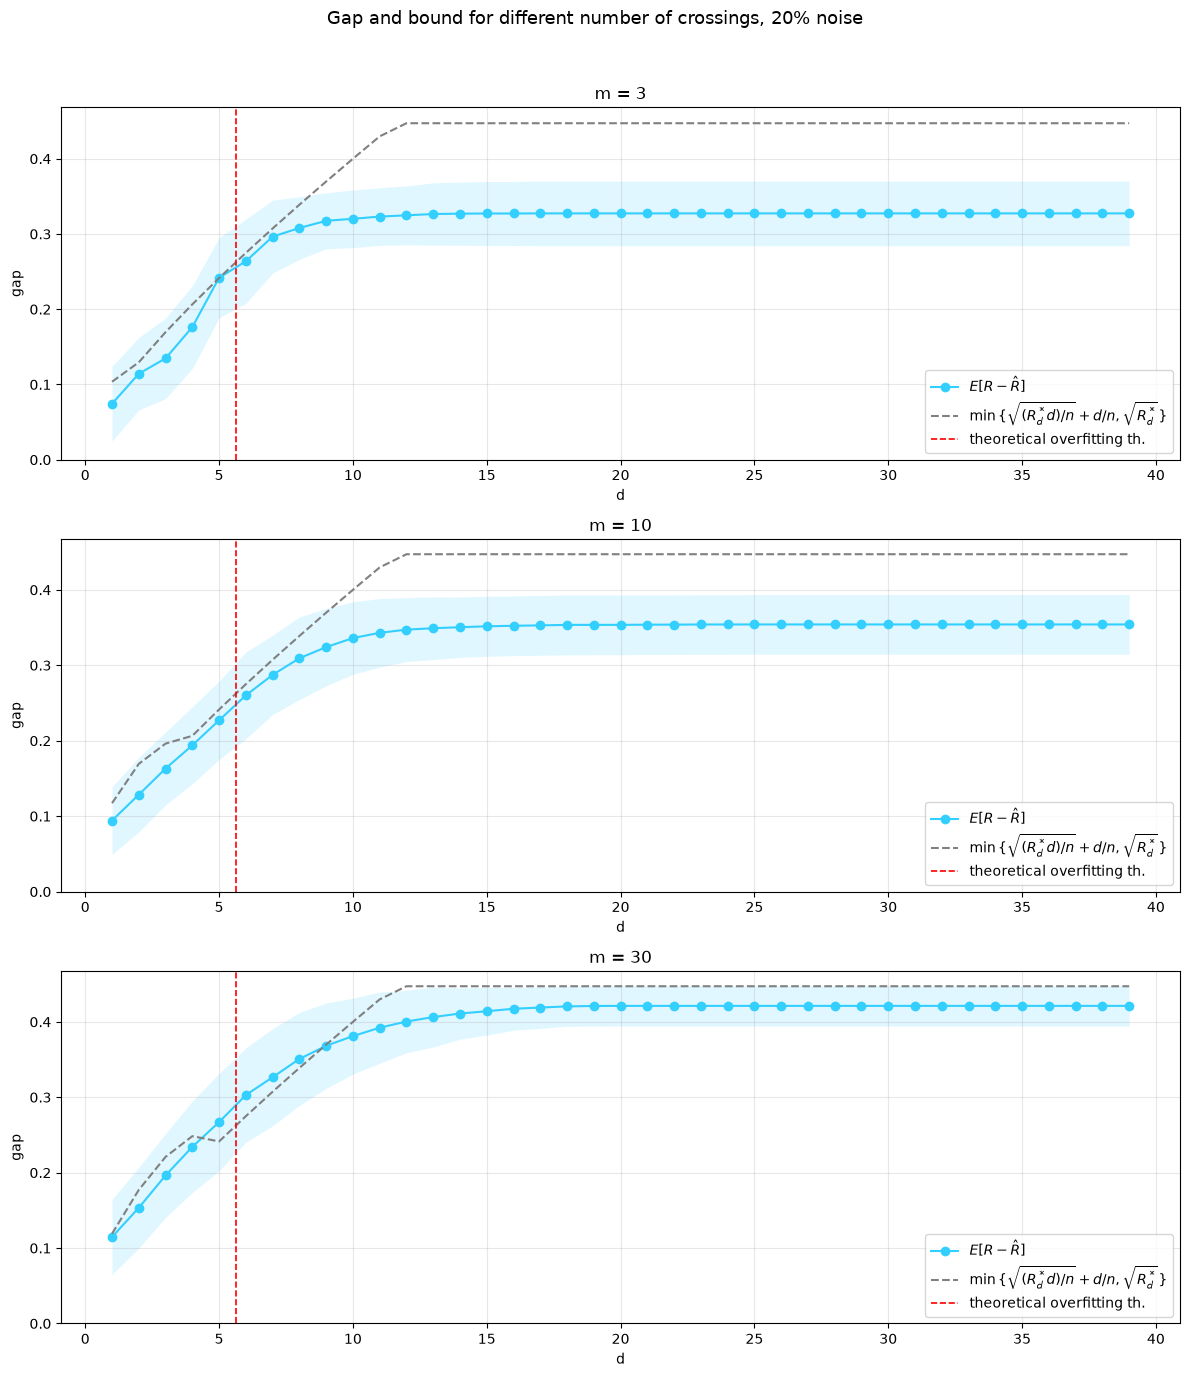

In [ ]:

fig, axs = plt.subplots(3, 1, figsize=(12, 14))

for ax, my_num_crossings in zip(axs.flat, my_nums_crossings):
    my_sine_f = partial(sine, m = my_num_crossings)
    my_R_star_d = dp_R_star_d(my_sine, depths, N = supp_size, p = noise_par)

    # build test set
    x_test = sample_x(data_size_test, supp_size)
    y_test = sample_y_bernoulli(x=x_test, f=my_sine_f, p=noise_par)

    # build models and do plots 
    hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
        x_test, y_test, n=data_size_tr, noise_type = "bernoulli",
        p=noise_par, T=num_iter, model=mymodel, f=my_smy_sine_fine, N=supp_size)
    plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps, 
          n=data_size_tr, noise_type = "bernoulli", p=noise_par, T=num_iter, model=mymodel, 
          one=False, three=False, axes=[ax],
          bound_name = "noiseapproxerr", bound_params = {"R_star_d": my_R_star_d})
    ax.set_title(f'm = {my_m}')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()